# Experiment 21 — held-out test data efficiency

Evaluation date: 28 October 2026. Each point uses that run's **minimum-validation-loss checkpoint**,
evaluated on the same **150 test structures** (7,200 Si and 14,400 O sites). No test score was used
to choose checkpoints. Experiment 21 is the cached **fully frozen backbone + trained scalar head**
experiment; ELoRA is a separate experiment and is not part of these curves.

Methods: **17** scratch (738,052 active parameters), **18** original frozen recipe (132),
**19** final interaction layer + head (141,380), **21** improved frozen recipe (132).
All use the same nested seed-42 fitting subsets, N = 10, 50, 100, 200, 800, and 50 validation structures.
Experiment 18 is shown as an unfinished baseline. All five runs in experiments 17, 19 and 21 reached
their configured early-stopping criterion; this does not establish a global optimisation optimum.

Targets are **absolute isotropic DFT shieldings**, `MS_Iso_QM = trace(ms)/3`, in ppm, rather than
referenced experimental chemical shifts. Test loss is
\[
L=\tfrac12\left[(\mathrm{RMSE}_{Si}/8.789599019755547)^2+
(\mathrm{RMSE}_{O}/19.197689920683118)^2\right].
\]
These fixed denominators were inherited from the full 800-structure training pool. N counts fitting
structures, not the additional validation labels or the E/F pretraining data.


## Main finding

The revised frozen-head recipe reduces test balanced loss by **14.0–40.8%** relative to the unfinished original frozen runs at matched training-set sizes. All five experiment 21 runs now reach early stopping. Nevertheless, **training the final interaction layer gives lower test loss at every matched N**. Final-layer transfer with just 10 fitting structures has loss 0.0590, below the improved frozen model with 800 structures (0.1152). These runs support an advantage from adapting the representation beyond optimising the frozen head. They do not establish a universal frozen-feature limit or isolate the effect of caching from the changed learning rate and longer training allowance.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, ScalarFormatter

BASE = Path.cwd()
if not (BASE / '21-Test-DataEfficiency-data').exists():
    BASE = BASE / 'experiments'
DATA = BASE / '21-Test-DataEfficiency-data'
FIG = BASE / '21-Test-DataEfficiency-figures'
FIG.mkdir(exist_ok=True)
metrics = pd.read_csv(DATA / 'metrics.csv')
test = metrics.query("split == 'test'").sort_values(['experiment', 'n']).copy()
valid = metrics.query("split == 'valid'").sort_values(['experiment', 'n']).copy()
audit = pd.read_csv(DATA / 'checkpoint-audit.csv')
manifest = json.loads((DATA / 'manifest.json').read_text())
paired = pd.read_csv(DATA / 'paired-test-comparisons.csv')
assert len(test) == len(valid) == 20
assert not manifest['test_used_for_training_or_selection']
assert np.allclose(valid.loss, valid.saved_valid_loss, rtol=5e-4, atol=1e-7)
assert audit.export_matches_checkpoint.all()
assert (audit.query('experiment == 21').status == 'Early stopping').all()
N = np.array([10, 50, 100, 200, 800])
COLORS = {17:'#386CB0', 18:'#D98535', 19:'#198C83', 21:'#8B4DB0'}
LABELS = {17:'17 · Scratch', 18:'18 · Frozen, original (unfinished)',
          19:'19 · Final layer + head', 21:'21 · Frozen, improved'}
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11, 'axes.titlesize':13,
                     'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':120,
                     'savefig.dpi':220, 'svg.fonttype':'none'})
def style(exp):
    return dict(color=COLORS[exp], marker='o', markersize=6, linewidth=2.2,
                linestyle='--' if exp==18 else '-',
                markerfacecolor='white' if exp==18 else COLORS[exp],
                alpha=.7 if exp==18 else 1, label=LABELS[exp])
def save(fig, stem):
    for ext in ('png', 'svg'):
        fig.savefig(FIG / (stem+'.'+ext), bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
print('Validated all 20 saved checkpoints and their independently recomputed validation losses.')
print('Test counts:', manifest['counts']['test'])


Validated all 20 saved checkpoints and their independently recomputed validation losses.
Test counts: {'structures': 150, 'atoms': 21600, 'Si': 7200, 'O': 14400}


## Primary curve: test element-balanced loss

Both axes below show explicit base-10 logarithms; the upper axis gives the actual training-set size.
Lower is better. Lines connect observed points only. There is one training seed per point.


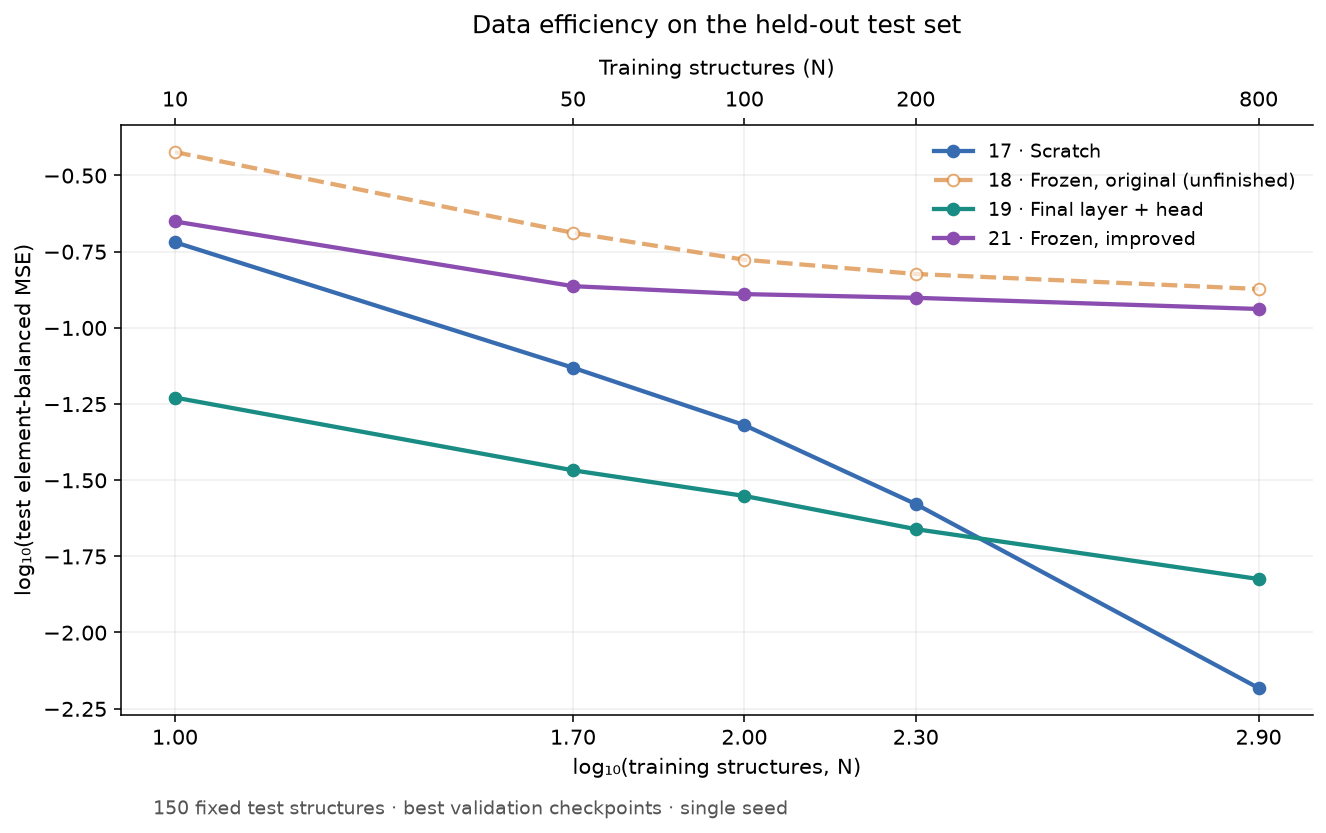

In [2]:
fig, ax = plt.subplots(figsize=(9.6, 5.8))
for exp in (17, 18, 19, 21):
    d = test.query('experiment == @exp').sort_values('n')
    ax.plot(np.log10(d.n), np.log10(d.loss), **style(exp))
ax.set_xticks(np.log10(N), [f'{x:.2f}' for x in np.log10(N)])
ax.set_xlabel('log₁₀(training structures, N)')
ax.set_ylabel('log₁₀(test element-balanced MSE)')
ax.set_title('Data efficiency on the held-out test set', pad=13)
ax.grid(alpha=.20)
top = ax.secondary_xaxis('top')
top.set_xticks(np.log10(N), N.astype(str))
top.set_xlabel('Training structures (N)', labelpad=8)
ax.legend(loc='best', frameon=False, fontsize=10)
fig.text(.12, -.015, '150 fixed test structures · best validation checkpoints · single seed', fontsize=10, color='#555555')
fig.tight_layout()
save(fig, '01-test-data-efficiency-loss')


## Element-specific errors

RMSE emphasises larger errors; MAE reports the average absolute site error. Elemental errors are
pooled over all test sites of that element. The x-axis is logarithmic and the error axes are linear.


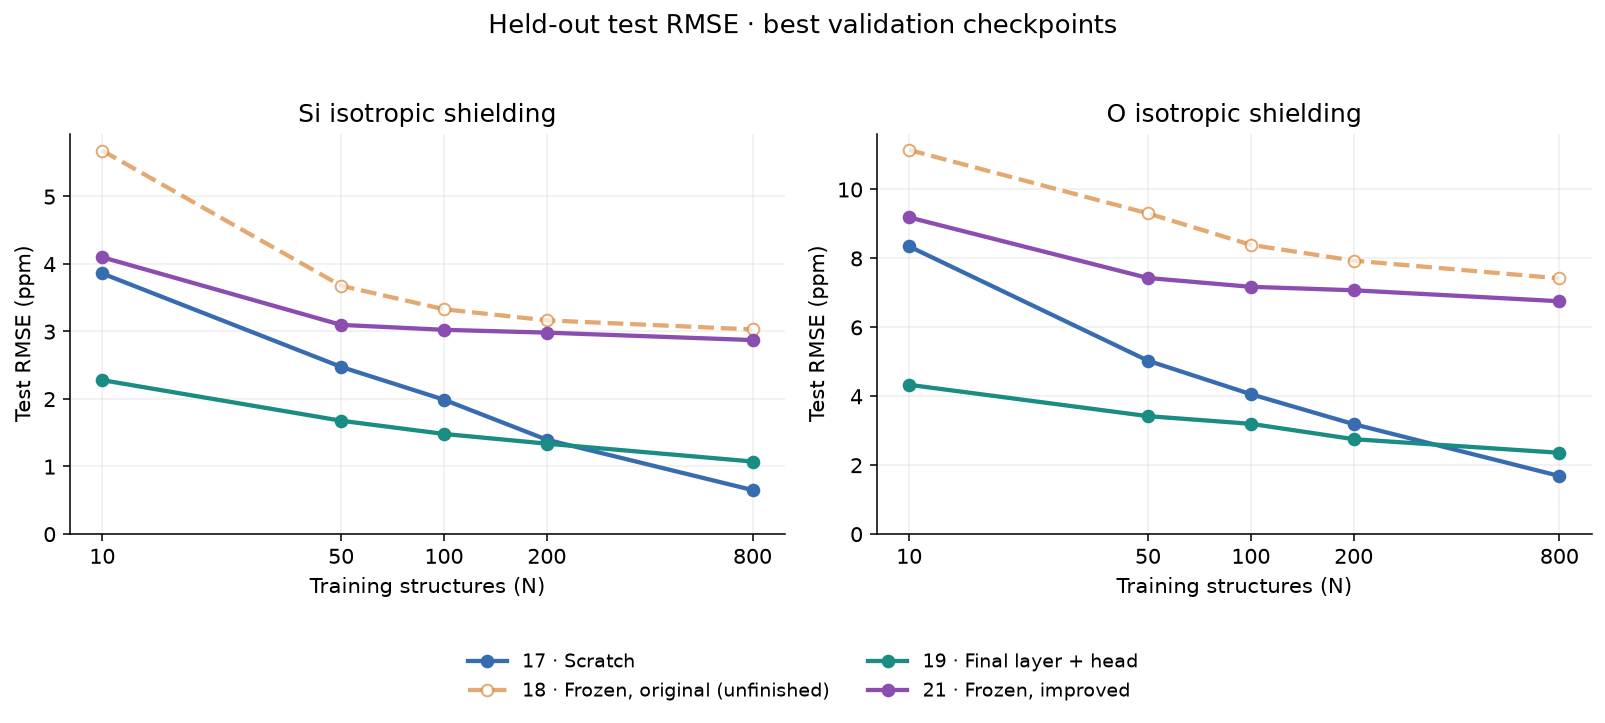

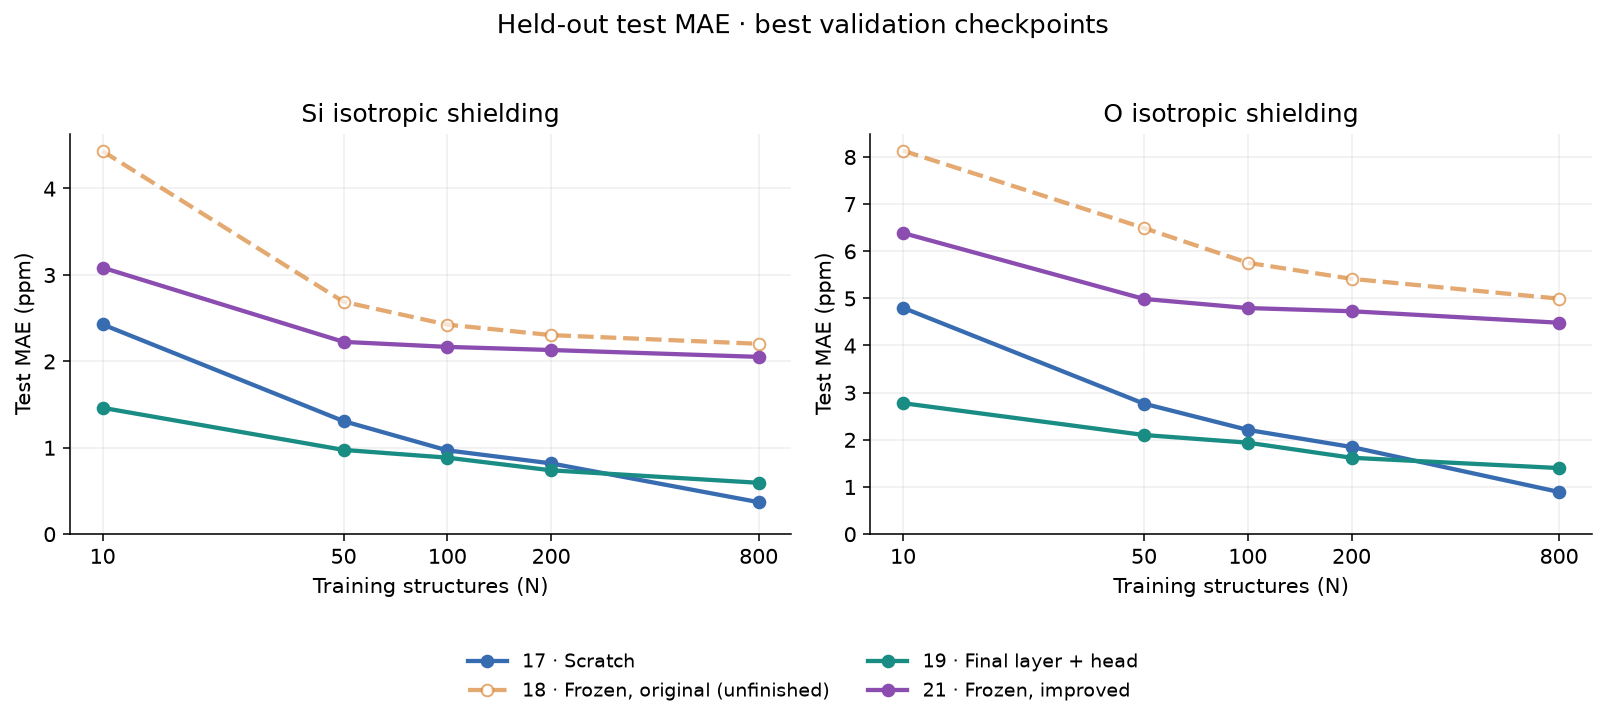

In [3]:
for metric, title in [('rmse', 'RMSE'), ('mae', 'MAE')]:
    fig, axs = plt.subplots(1, 2, figsize=(11.6, 4.8))
    for ax, elem in zip(axs, ['Si', 'O']):
        for exp in (17, 18, 19, 21):
            d = test.query('experiment == @exp').sort_values('n')
            ax.plot(d.n, d[elem+'_'+metric], **style(exp))
        ax.set_xscale('log')
        ax.set_xticks(N, N.astype(str))
        ax.xaxis.set_minor_locator(FixedLocator([]))
        ax.set_xlabel('Training structures (N)')
        ax.set_ylabel('Test '+title+' (ppm)')
        ax.set_title(elem+' isotropic shielding')
        ax.grid(alpha=.2)
        ax.set_ylim(bottom=0)
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5,-.025), ncol=2, frameon=False, fontsize=10)
    fig.suptitle('Held-out test '+title+' · best validation checkpoints', y=1.025)
    fig.tight_layout(rect=(0,.12,1,1))
    save(fig, '02-test-data-efficiency-rmse' if metric=='rmse' else '03-test-data-efficiency-mae')


## Experiment 21 results and matched comparisons


In [4]:
result21 = test.query('experiment == 21').sort_values('n')
cols = ['n','best_epoch','final_epoch','loss','Si_rmse','O_rmse','Si_mae','O_mae']
print(result21[cols].to_string(index=False, float_format=lambda x:f'{x:.6f}'))
result21[cols].to_csv(DATA / 'experiment21-test-summary.csv', index=False)
comparison = []
for n in N:
    a = result21.query('n == @n').iloc[0]
    row = {'n':int(n)}
    for exp in (17,18,19):
        b = test.query('n == @n and experiment == @exp').iloc[0]
        row[f'loss_reduction_vs_{exp}_percent'] = 100*(1-a.loss/b.loss)
    comparison.append(row)
comparison = pd.DataFrame(comparison)
comparison.to_csv(DATA / 'relative-test-loss-comparisons.csv', index=False)
print('\nPositive percentage = lower loss for experiment 21; negative = higher loss.')
print(comparison.to_string(index=False, float_format=lambda x:f'{x:.2f}'))
print('\nAll methods:')
print(test[['experiment','n','loss','Si_rmse','O_rmse','Si_mae','O_mae']].to_string(index=False, float_format=lambda x:f'{x:.6f}'))


  n  best_epoch  final_epoch     loss  Si_rmse   O_rmse   Si_mae    O_mae
 10        4704         5004 0.223188 4.099186 9.184377 3.083497 6.383580
 50        5361         5661 0.136895 3.097032 7.426261 2.223886 4.985028
100        3618         3918 0.128939 3.023868 7.170840 2.165709 4.791655
200        2676         2976 0.125363 2.982202 7.069612 2.129537 4.723858
800        1697         1997 0.115225 2.871831 6.751919 2.050054 4.480272

Positive percentage = lower loss for experiment 21; negative = higher loss.
  n  loss_reduction_vs_17_percent  loss_reduction_vs_18_percent  loss_reduction_vs_19_percent
 10                        -16.98                         40.82                       -278.31
 50                        -85.18                         33.18                       -302.00
100                       -169.15                         22.87                       -359.58
200                       -375.16                         16.49                       -474.25
800      

## Interpretation of the observed curves

The following comparisons use the preselected checkpoints at matched N. The percentage comparisons
refer to the balanced **squared-error loss**, not percentage changes in RMSE. They describe the
observed runs and do not select a new model or training recipe using the test set.


In [5]:
p = test.pivot(index='n', columns='experiment', values='loss')
reduction = 100*(1-p[21]/p[18])
print(f'Experiment 21 versus original frozen recipe: test loss reductions of {reduction.min():.1f}% to {reduction.max():.1f}% across the five sizes.')
print('Final-layer transfer has lower test loss than experiment 21 at N =', list(p.index[p[19] < p[21]]))
print('Scratch has lower test loss than experiment 21 at N =', list(p.index[p[17] < p[21]]))
print(f'Experiment 21, N=50 to N=800: {100*(1-p.loc[800,21]/p.loc[50,21]):.1f}% lower test loss for 16 times as many fitting structures.')
print(f'At N=800, experiment 21 loss / final-layer transfer loss = {p.loc[800,21]/p.loc[800,19]:.2f}.')
print(f'At N=800, experiment 21 loss / scratch loss = {p.loc[800,21]/p.loc[800,17]:.2f}.')
print(f'Final-layer transfer with N=10: {p.loc[10,19]:.6f}; improved frozen backbone with N=800: {p.loc[800,21]:.6f}.')
print('Reaching patience 300 removes the earlier unfinished-run qualification for experiment 21; it does not prove an irreducible frozen-feature error floor.')


Experiment 21 versus original frozen recipe: test loss reductions of 14.0% to 40.8% across the five sizes.
Final-layer transfer has lower test loss than experiment 21 at N = [10, 50, 100, 200, 800]
Scratch has lower test loss than experiment 21 at N = [10, 50, 100, 200, 800]
Experiment 21, N=50 to N=800: 15.8% lower test loss for 16 times as many fitting structures.
At N=800, experiment 21 loss / final-layer transfer loss = 7.69.
At N=800, experiment 21 loss / scratch loss = 17.53.
Final-layer transfer with N=10: 0.058997; improved frozen backbone with N=800: 0.115225.
Reaching patience 300 removes the earlier unfinished-run qualification for experiment 21; it does not prove an irreducible frozen-feature error floor.


## Paired uncertainty in the test comparison

The table uses 2,000 paired bootstrap resamples of whole test structures, retaining all sites within
each structure. Delta is experiment 21 RMSE minus comparator RMSE; a negative interval favours 21.
These intervals measure sensitivity to the sampled test structures **conditional on the fitted models**.
They do not measure training-seed variation, account for correlations between distinct structures,
or provide a multiple-comparison-corrected significance test.


In [6]:
print(paired.sort_values(['comparator','n']).to_string(index=False, float_format=lambda x:f'{x:.4f}'))


  n  comparator  Si_rmse_delta  Si_delta_low  Si_delta_high  O_rmse_delta  O_delta_low  O_delta_high
 10          17         0.2407       -0.0802         0.5435        0.8414      -0.0403        1.6707
 50          17         0.6220        0.2977         0.8969        2.3996       2.1631        2.6589
100          17         1.0351        0.7474         1.3062        3.1158       2.9129        3.3279
200          17         1.5863        1.4001         1.7723        3.8835       3.5437        4.2330
800          17         2.2216        2.0616         2.4163        5.0705       4.5970        5.5883
 10          18        -1.5798       -1.6881        -1.4659       -1.9580      -2.1698       -1.7492
 50          18        -0.5800       -0.6970        -0.4688       -1.8746      -2.0260       -1.7424
100          18        -0.3048       -0.3753        -0.2232       -1.2178      -1.3447       -1.1087
200          18        -0.1822       -0.2439        -0.1026       -0.8601      -0.9492     

## Optimisation and checkpoint audit

Epochs are one-based. Experiment 21 uses a 0.03 scale learning rate, versus 0.003 for the
head/offsets, and a 10,000-epoch ceiling. Experiment 18 used the original 0.003 recipe and
3,000-epoch ceiling. Thus the comparison tests the revised training recipe and additional
optimisation, not feature caching alone or equal compute. No speedup claim is made here:
the saved logger runtime is not independently audited end-to-end timing including cache construction.


In [7]:
print(audit.sort_values(['experiment','n'])[
    ['experiment','n','best_epoch','final_epoch','checks_since_best','status','export_matches_checkpoint']
].to_string(index=False))
v = valid.set_index('run_id').loss
t = test.set_index('run_id').loss
check = pd.DataFrame({'recomputed_valid_loss':v, 'test_loss':t})
check['test_over_valid'] = check.test_loss / check.recomputed_valid_loss
check.to_csv(DATA / 'validation-test-diagnostic.csv')
print('\nExperiment 21 validation/test diagnostic (test is not used for selection):')
print(check.loc[result21.run_id].to_string(float_format=lambda x:f'{x:.6f}'))
print('\nExact rounded ordered-geometry overlaps within NMR splits:', manifest['geometry_overlap'])
print('E/F pretraining geometry overlap with NMR test:', manifest['ef_pretraining_test_geometry_overlap'])


 experiment   n  best_epoch  final_epoch  checks_since_best                     status  export_matches_checkpoint
         17  10          62          362                300             Early stopping                       True
         17  50          90          390                300             Early stopping                       True
         17 100         110          410                300             Early stopping                       True
         17 200         114          414                300             Early stopping                       True
         17 800         237          537                300             Early stopping                       True
         18  10        3000         3000                  0              Epoch ceiling                       True
         18  50        2851         2851                  0 Stopped before convergence                       True
         18 100        2996         3000                  4              Epoch ceiling  

## Reproducibility and scope

`metrics.csv` contains all 40 validation/test evaluations; `checkpoint-audit.csv` records selected
epochs and stopping status. `test-predictions.npz` and `valid-predictions.npz` store site references,
atomic numbers, structure indices and one prediction array per run. `structure-metrics.csv` supports
the paired bootstrap. `manifest.json` records source SHA-256 hashes, split counts, numerical precision,
normalisation and checks. `evaluate.py` reruns inference in the repository's Python environment;
this notebook redraws figures from the saved metrics without retraining or selecting models.

Predictions were freshly computed in CPU float32, with metrics accumulated in float64. Frozen-model
feature reuse was allowed only after exact backbone-state equality checks and was checked against full
forward predictions on the first, middle and last structure of each evaluation split for every frozen model.
Recomputed validation losses agree with the saved selection scores (relative tolerance 0.05%).
Every exported `model.pt` also matches its `best.ckpt` state. Input hashes were unchanged after evaluation.

The geometry audit uses ordered atomic numbers, positions/cell rounded to 1e-6 Å and PBC flags.
It does not rule out reordered duplicates, related configurations or temporal correlations. If E/F
pretraining overlap is nonzero, these are held-out NMR labels, not completely unseen geometries.
The curves describe this dataset and these single-seed runs; repeated seeds and an independently
grouped split would be needed to assess robustness more broadly. Future hyperparameter decisions
should continue to use validation data rather than these test scores.
